# FER2013 experiments

In [1]:
import os
if not os.path.isdir('/content/elec-lab-3'):
    !git clone -q https://github.com/masud1901/elec-lab-3.git /content/elec-lab-3
%cd /content/elec-lab-3
!git pull -q
!pip -q install -r requirements.txt transformers

/content/elec-lab-3


In [2]:
from google.colab import drive
drive.mount('/content/drive')   # results are copied here so a disconnect doesn't lose them

Mounted at /content/drive


In [3]:
!python experiments.py --profile sprint --arms all   # or: --arms A   /   --arms B

profile sprint: 8 epochs per arm (x2 for longer-schedule arms) | 7 arm(s)

>>> A1_ex1_baseline_resnet18_128px  [1]  ~6 min on a T4
    /usr/bin/python3 -u train.py --img-size 128 --batch-size 128 --epochs 8 --out-dir runs
epoch  1/8 | step   21/211 | loss 2.668 | lr 2.82e-05 |  694 img/s
epoch  1/8 | step   42/211 | loss 2.519 | lr 5.21e-05 | 1036 img/s
epoch  1/8 | step   63/211 | loss 2.411 | lr 9.02e-05 | 1240 img/s
epoch  1/8 | step   84/211 | loss 2.338 | lr 1.40e-04 | 1375 img/s
epoch  1/8 | step  105/211 | loss 2.263 | lr 1.98e-04 | 1470 img/s
epoch  1/8 | step  126/211 | loss 2.206 | lr 2.60e-04 | 1537 img/s
epoch  1/8 | step  147/211 | loss 2.163 | lr 3.22e-04 | 1589 img/s
epoch  1/8 | step  168/211 | loss 2.125 | lr 3.80e-04 | 1631 img/s
epoch  1/8 | step  189/211 | loss 2.086 | lr 4.29e-04 | 1666 img/s
epoch  1/8 | step  210/211 | loss 2.045 | lr 4.68e-04 | 1696 img/s
epoch  1/8 | step  211/211 | loss 2.044 | lr 4.69e-04 | 1693 img/s
epoch  1/8 | train loss 2.044 | val loss 

# Results

Sorted by macro-F1 (the main score); accuracy is for comparison with published papers.

| exercise   | arm                                                                                                      | model           |   img | stem     | pretrained   |   epochs |   accuracy |   macro_f1 |   minutes |
|:-----------|:---------------------------------------------------------------------------------------------------------|:----------------|------:|:---------|:-------------|---------:|-----------:|-----------:|----------:|
|            | resnet18_ferplus_majority_128px_sqrt_inverse_e8                                                          | resnet18        |   128 | standard | True         |        8 |     0.8412 |     0.6935 |       3.1 |
|            | efficientnet_b0_ferplus_majority_128px_sqrt_inverse_e8_lr0.001_mixup0.2_ema0.999                         | efficientnet_b0 |   128 | standard | True         |        8 |     0.8261 |     0.682  |       4.7 |
|        

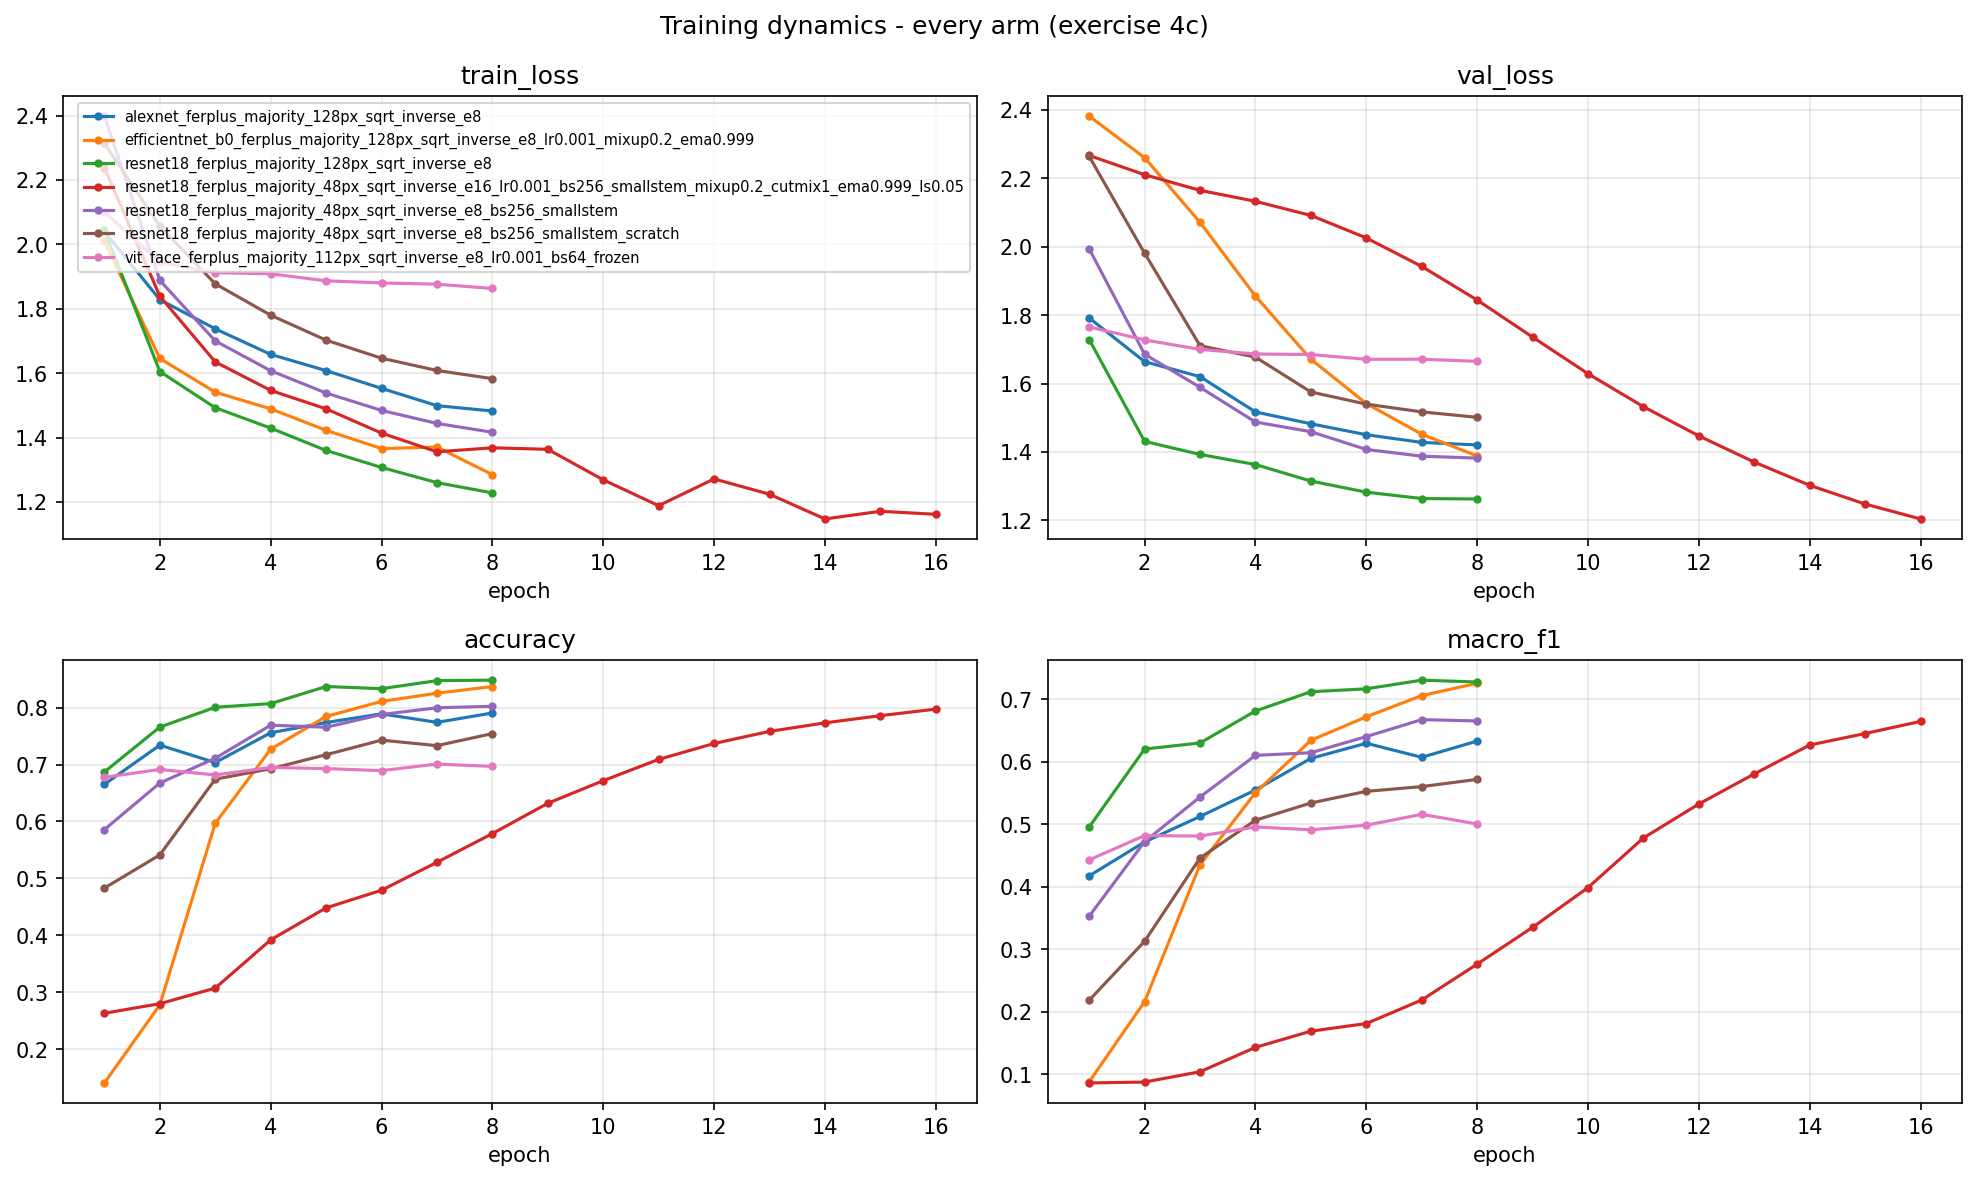

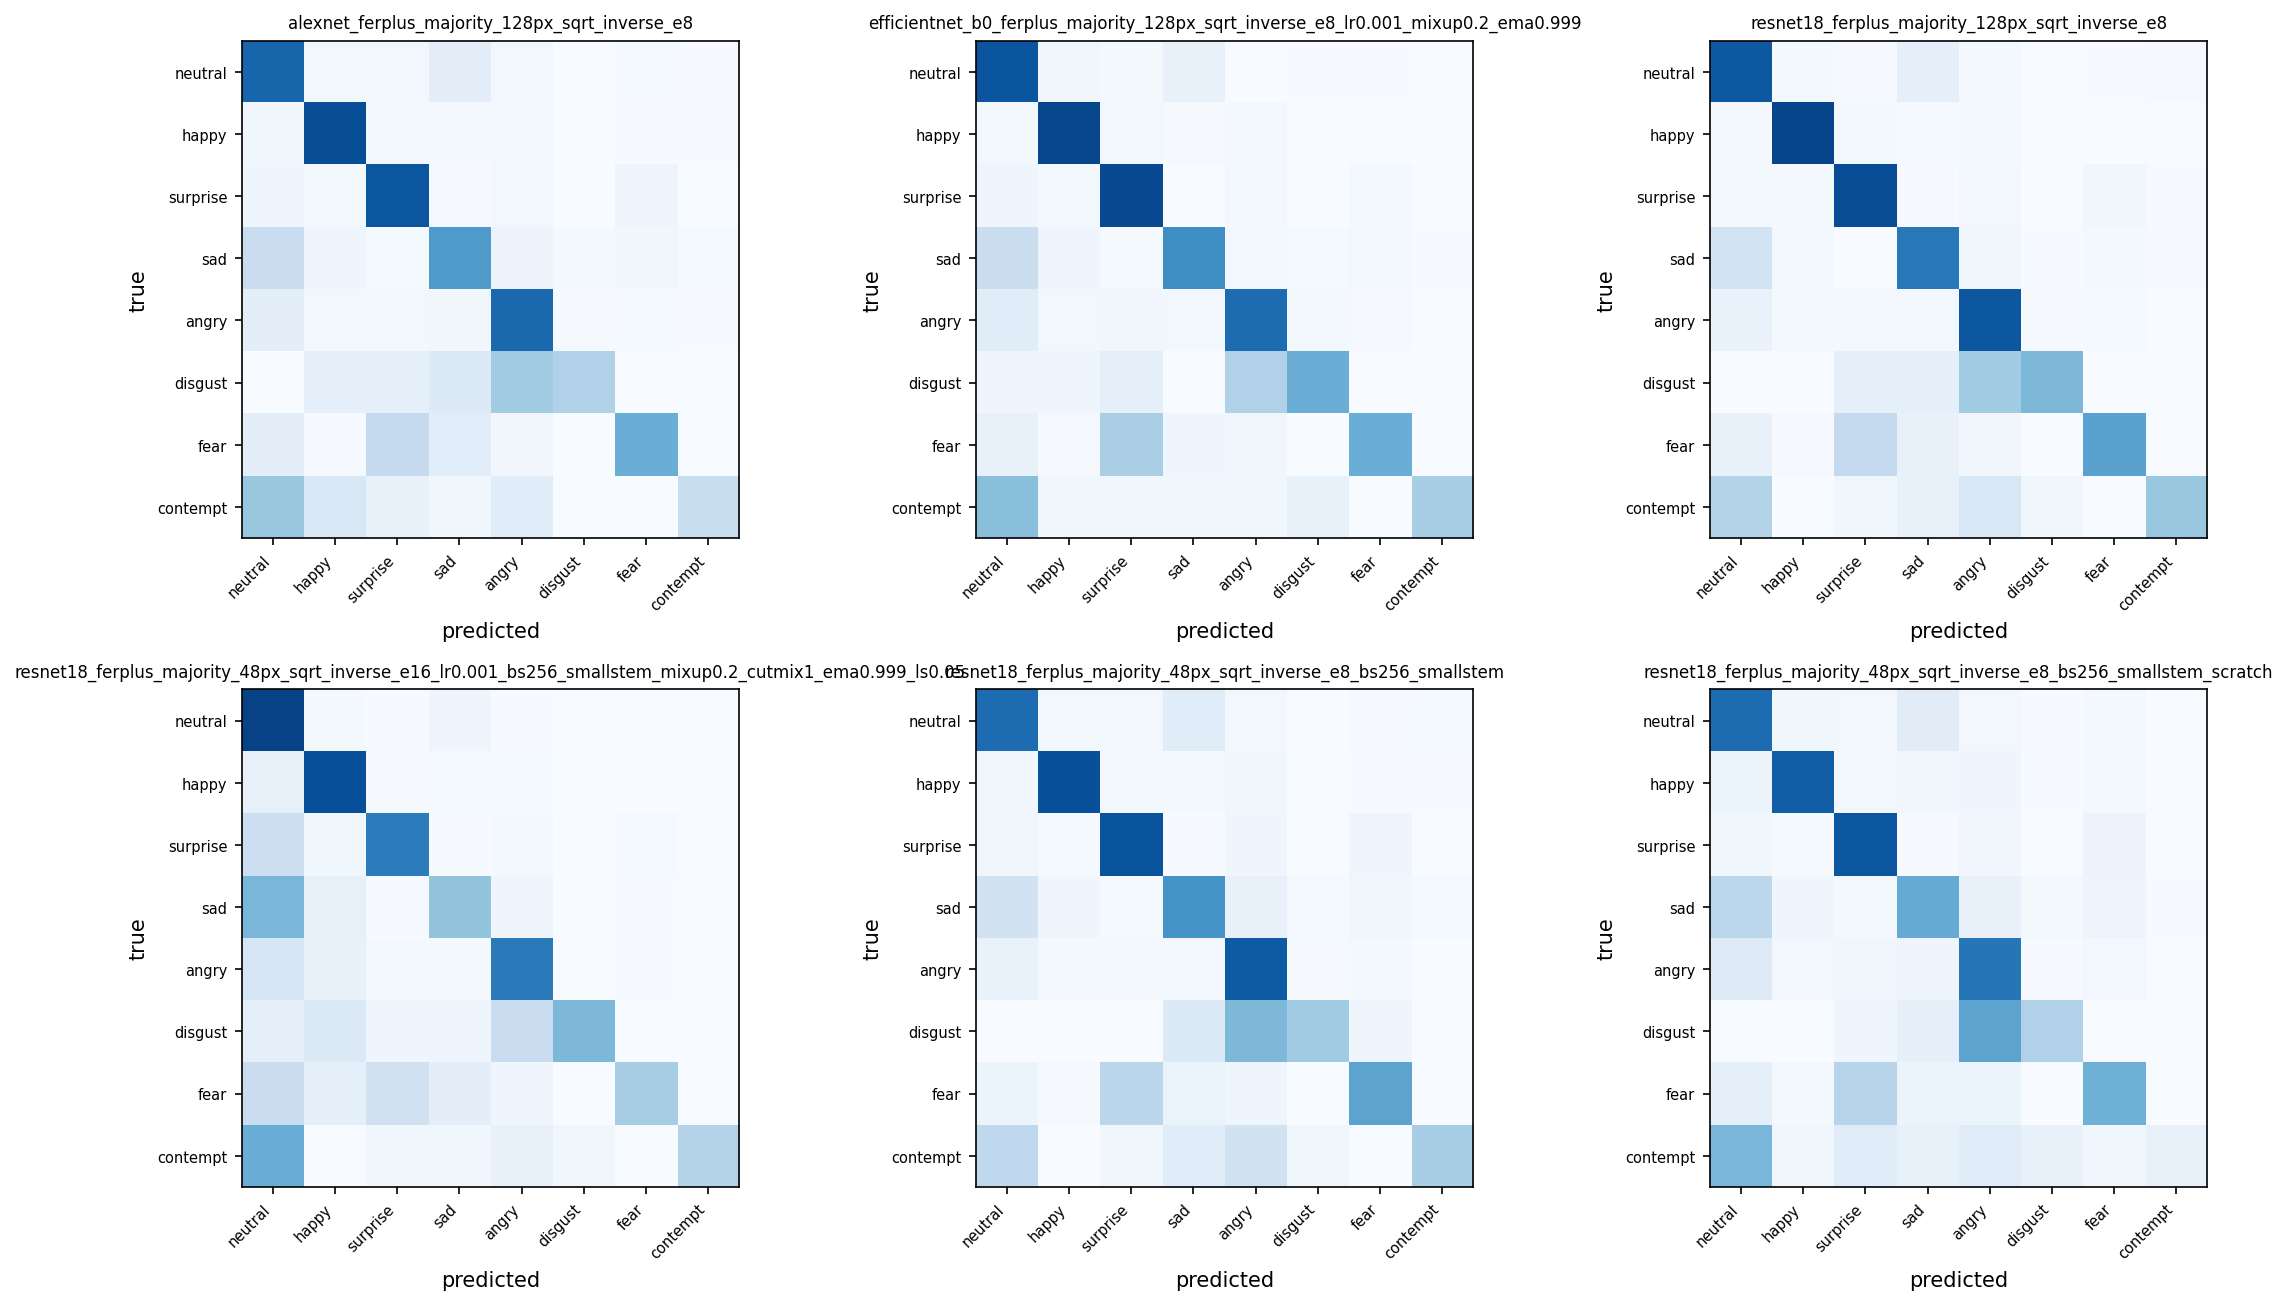

In [4]:
!cp -r runs /content/drive/MyDrive/fer_runs_results
print(open('runs/RESULTS.md').read())
from IPython.display import Image, display
for f in ['learning_curves_all.png','confusion_matrices_all.png']: display(Image('runs/'+f))



exercise                                                                                                      arm           model  img     stem  pretrained  epochs  accuracy  macro_f1  minutes
                                                                  resnet18_ferplus_majority_128px_sqrt_inverse_e8        resnet18  128 standard        True       8    0.8412    0.6935      3.1
                                 efficientnet_b0_ferplus_majority_128px_sqrt_inverse_e8_lr0.001_mixup0.2_ema0.999 efficientnet_b0  128 standard        True       8    0.8261    0.6820      4.7
         resnet18_ferplus_majority_48px_sqrt_inverse_e16_lr0.001_bs256_smallstem_mixup0.2_cutmix1_ema0.999_ls0.05        resnet18   48    small        True      16    0.7775    0.6483      3.2
                                                   resnet18_ferplus_majority_48px_sqrt_inverse_e8_bs256_smallstem        resnet18   48    small        True       8    0.7829    0.6281      1.9
                                  

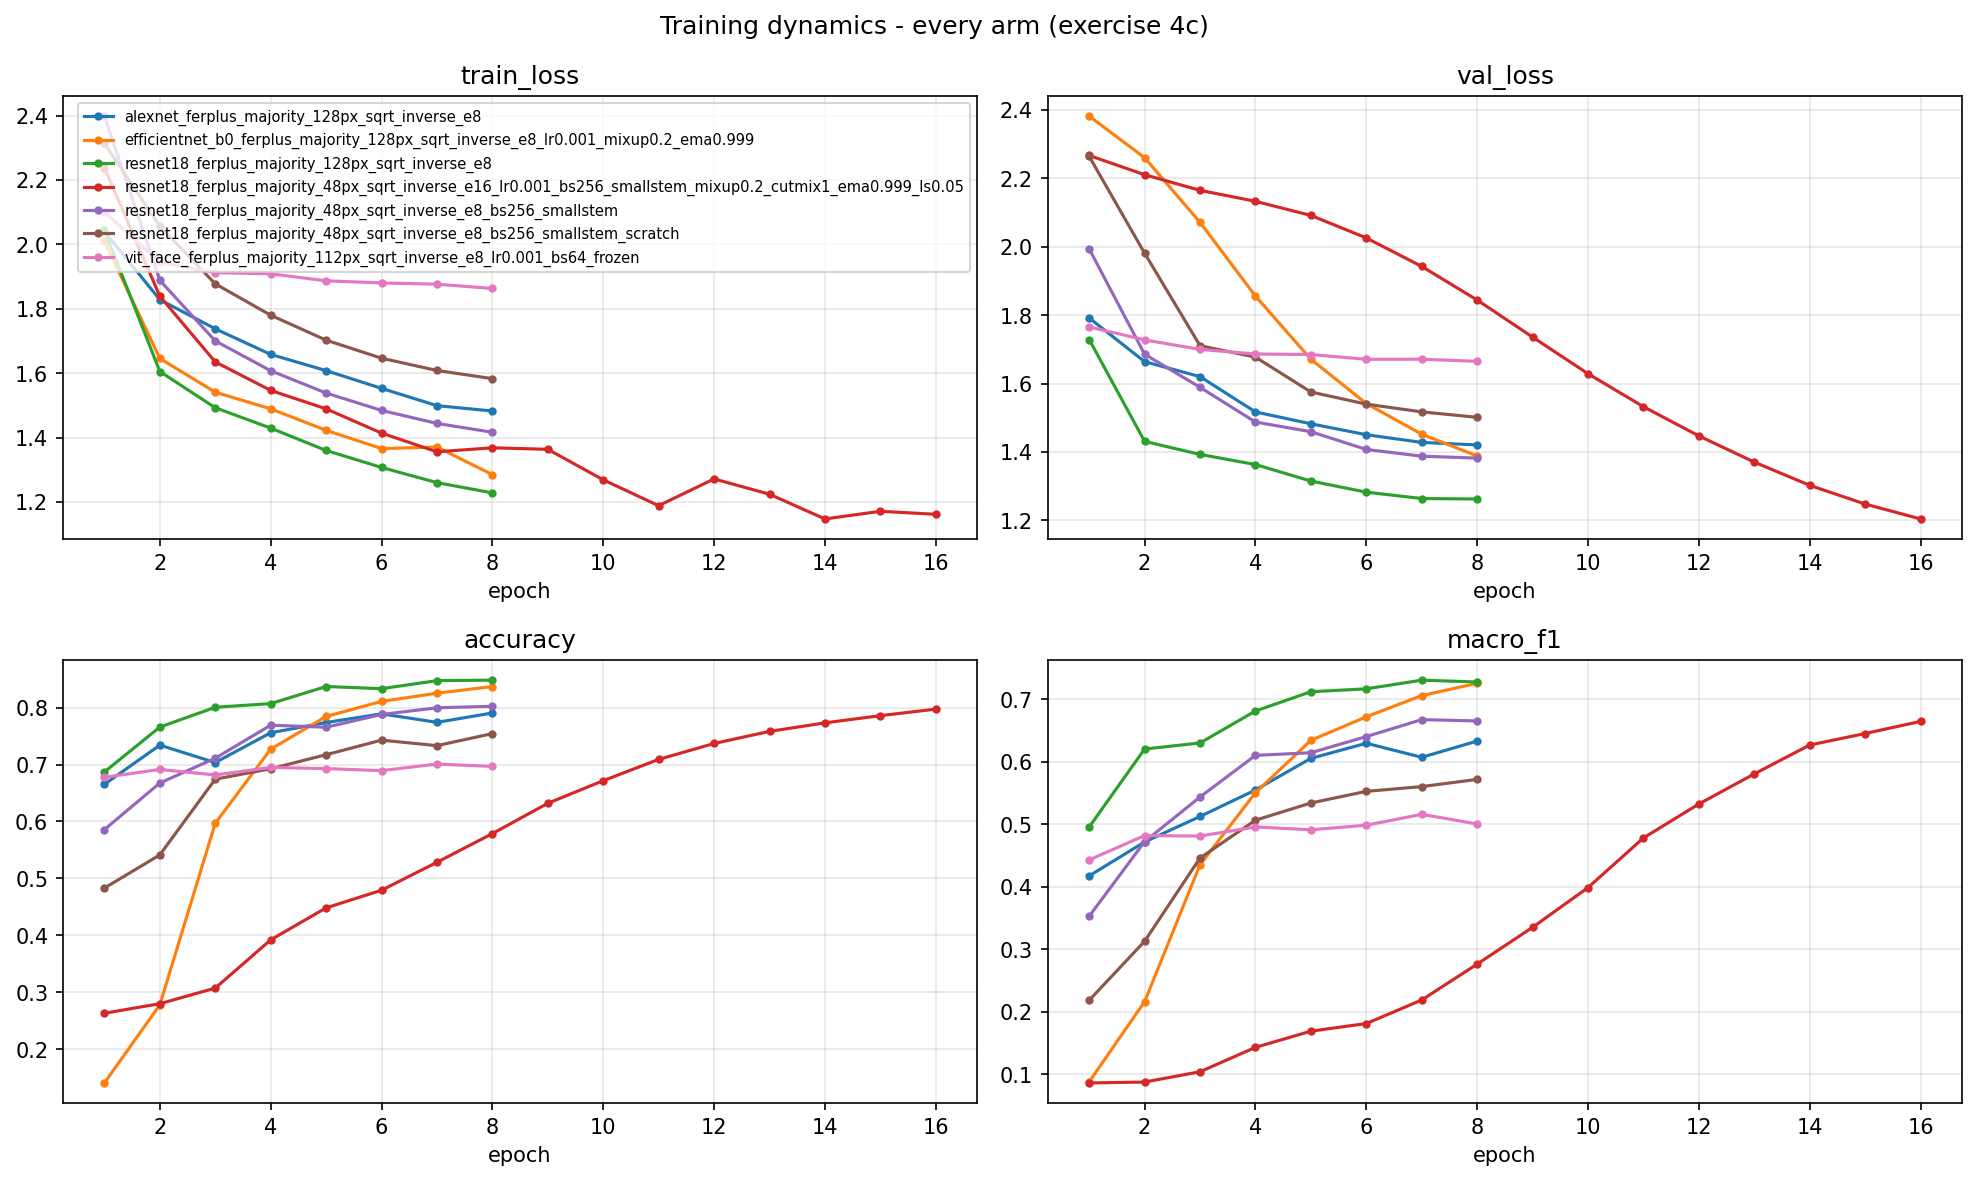

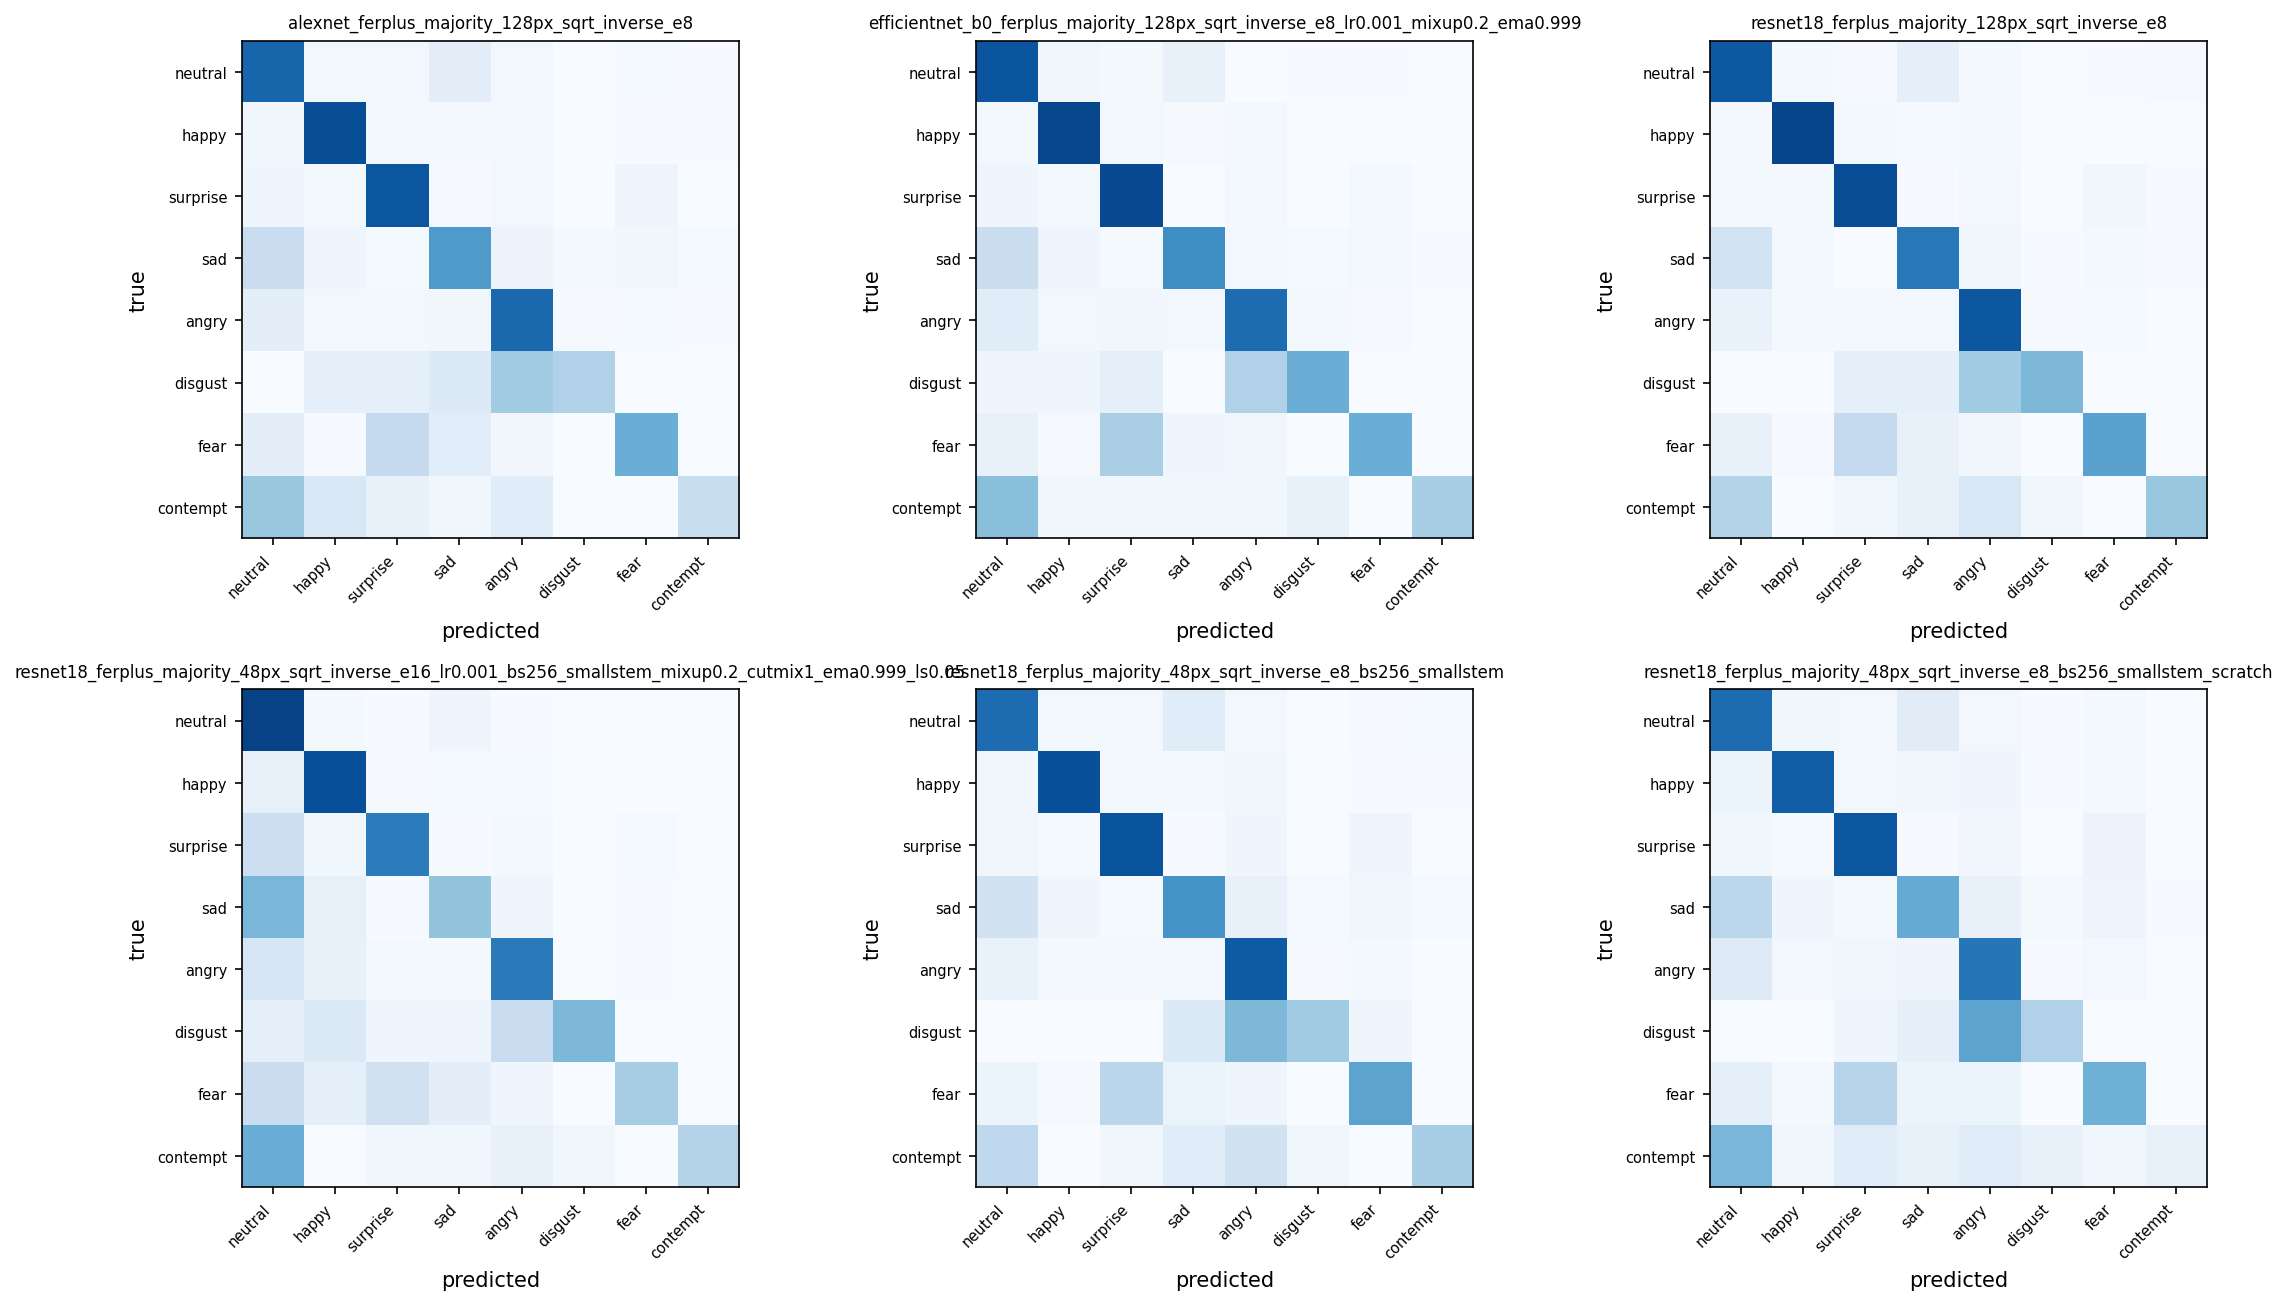

In [5]:
!python experiments.py --skip-training
print(open('runs/RESULTS.md').read())
from IPython.display import Image, display
for f in ['learning_curves_all.png', 'confusion_matrices_all.png']:
    display(Image('runs/' + f))

Device: Tesla T4
/content/ayon.jpg
  happy     73.8%
  contempt  8.8%
  disgust   6.6%
  saved /content/ayon_prediction.png
/content/catto.jpg
  no face found (or face detector unavailable), using the whole image
  sad       25.2%
  happy     18.3%
  neutral   15.0%
  saved /content/catto_prediction.png


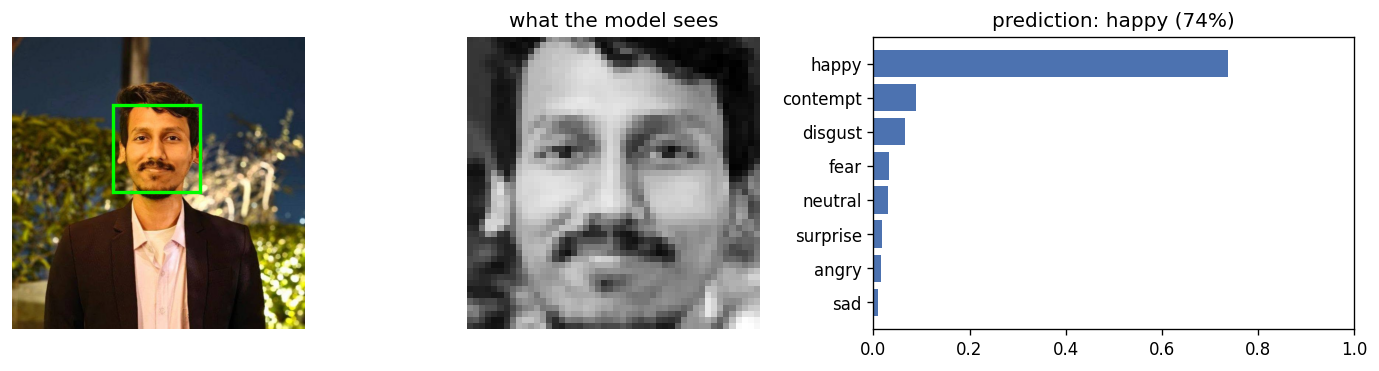

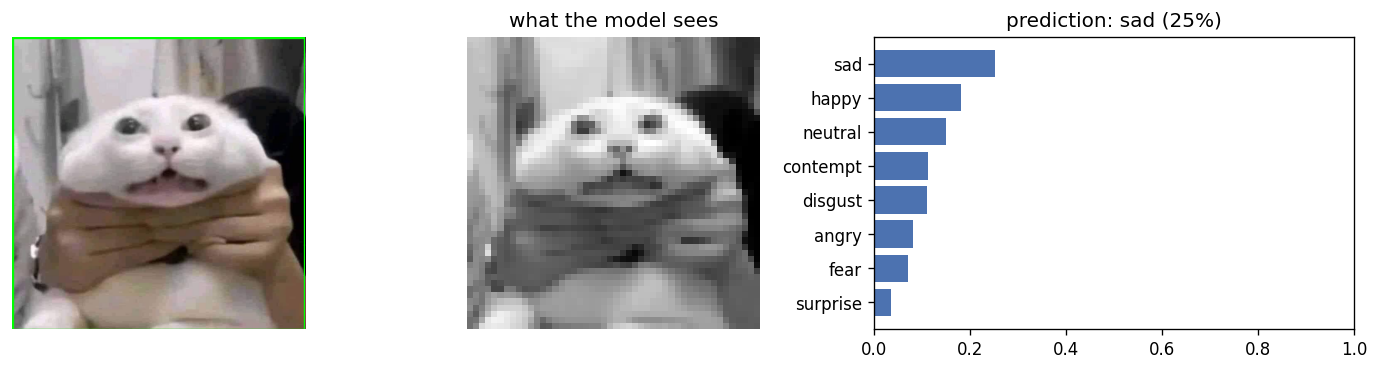

In [6]:
import glob
best = 'runs/resnet18_ferplus_majority_128px_sqrt_inverse_e8/best.pt'   # A1, best test macro-F1
photos = sorted(glob.glob('/content/*.jpg') + glob.glob('/content/*.jpeg') + glob.glob('/content/*.png'))
!python predict.py --checkpoint {best} {' '.join(photos)}
from IPython.display import Image, display
for p in sorted(glob.glob('/content/*_prediction.png')):
    display(Image(p))